<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/general_relativity/gr_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*General Relativity* — `gr_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# GR Ch3 Figures — Introducing Riemannian Geometry
**Figures:**
1. `gr_ch3_fig01_lightcone.png` — lightcone at a point (timelike/null/spacelike)
2. `gr_ch3_fig02_parallel_transport.png` — path-dependent parallel transport on S²
3. `gr_ch3_fig03_normal_coords.png` — exponential map / normal coordinates
4. `gr_ch3_fig04_holonomy.png` — holonomy: vector transported around a loop on S²

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Ellipse, FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D
import os

os.makedirs('figures', exist_ok=True)

BG     = '#0d1117'
GOLD   = '#d4a017'
BLUE   = '#388bfd'
GREEN  = '#3fb950'
RED    = '#f85149'
PURPLE = '#bc8cff'
MUTED  = '#8b949e'
TEXT   = '#e6edf3'
ORANGE = '#f0883e'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': TEXT, 'axes.labelcolor': TEXT,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.edgecolor': MUTED, 'grid.color': '#21262d',
    'font.family': 'DejaVu Sans', 'mathtext.fontset': 'dejavusans',
})
print('Setup done.')

Setup done.


## Fig 1: Lightcone at point p

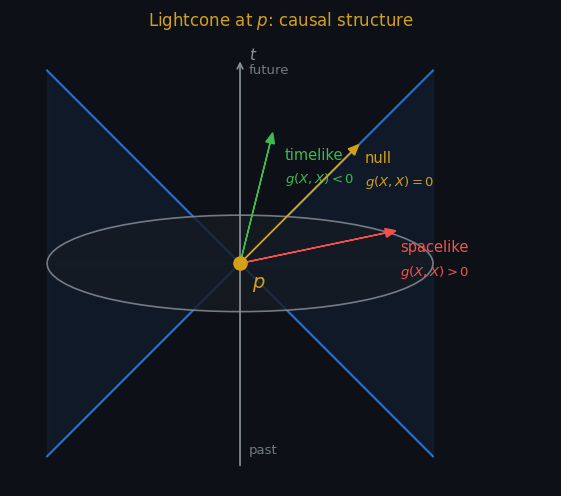

Fig 1 saved.


In [2]:
fig, ax = plt.subplots(figsize=(5.5, 5.5), facecolor=BG)
ax.set_facecolor(BG); ax.set_aspect('equal'); ax.axis('off')

from matplotlib.patches import Ellipse

# Four cone lines only
for sx in [-1, 1]:
    ax.plot([0, sx*1.3], [0,  1.3], color=BLUE, lw=1.5, alpha=0.75)
    ax.plot([0, sx*1.3], [0, -1.3], color=BLUE, lw=1.5, alpha=0.75)

ax.fill_between([-1.3, 0, 1.3], [1.3, 0, 1.3], color=BLUE, alpha=0.07)
ax.fill_between([-1.3, 0, 1.3], [-1.3, 0, -1.3], color=BLUE, alpha=0.07)

ell = Ellipse((0, 0), 2.6, 0.65, facecolor='#161b22',
              edgecolor=MUTED, lw=1.2, alpha=0.8, zorder=3)
ax.add_patch(ell)

ax.scatter([0],[0], color=GOLD, s=90, zorder=10)
ax.text(0.08, -0.16, r'$p$', color=GOLD, fontsize=14, fontweight='bold', zorder=11)

akw = dict(head_width=0.06, head_length=0.07, length_includes_head=True, zorder=8)
ax.arrow(0,0, 0.22,0.88, color=GREEN, **akw)
ax.text(0.30, 0.70, 'timelike', color=GREEN, fontsize=10.5, ha='left')
ax.text(0.30, 0.55, r'$g(X,X)<0$', color=GREEN, fontsize=9.5, ha='left')

ax.arrow(0,0, 0.80,0.80, color=GOLD, **akw)
ax.text(0.84, 0.68, 'null', color=GOLD, fontsize=10.5, ha='left')
ax.text(0.84, 0.53, r'$g(X,X)=0$', color=GOLD, fontsize=9.5, ha='left')

ax.arrow(0,0, 1.05,0.22, color=RED, **akw)
ax.text(1.08, 0.08, 'spacelike', color=RED, fontsize=10.5, ha='left')
ax.text(1.08,-0.08, r'$g(X,X)>0$', color=RED, fontsize=9.5, ha='left')

ax.annotate('', xy=(0, 1.38), xytext=(0, -1.38),
            arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))
ax.text(0.06,  1.28, 'future', color=MUTED, fontsize=9.5, ha='left', alpha=0.8)
ax.text(0.06, -1.28, 'past',   color=MUTED, fontsize=9.5, ha='left', alpha=0.8)
ax.text(0.06,  1.38, r'$t$',   color=MUTED, fontsize=11, ha='left')

ax.set_xlim(-1.55, 2.1); ax.set_ylim(-1.5, 1.55)
ax.set_title(r'Lightcone at $p$: causal structure', color=GOLD, fontsize=12, pad=6)
plt.tight_layout(pad=0.3)
plt.savefig('figures/gr_ch3_fig01_lightcone.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 1 saved.')


## Fig 2: Path-dependent Parallel Transport on S²

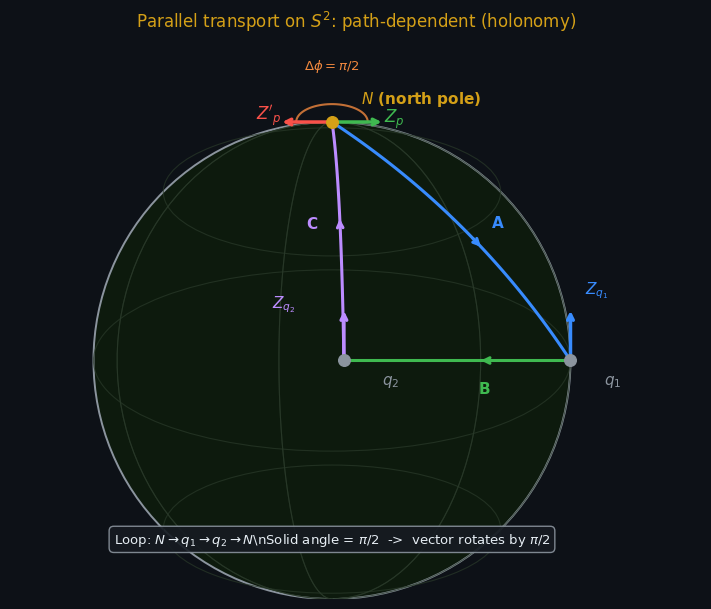

Fig 2 saved.


In [3]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(7, 6), facecolor=BG)
ax.set_facecolor(BG); ax.set_aspect('equal'); ax.axis('off')

ASPECT = 0.38

sphere_bg = Ellipse((0,0), 2.0, 2.0, facecolor='#0d1a0d', edgecolor=MUTED, lw=1.4)
ax.add_patch(sphere_bg)

for lat_frac in [0.25, 0.5, 0.75]:
    lat = np.pi * lat_frac
    r_lat = np.sin(lat); z_lat = np.cos(lat)
    ax.add_patch(Ellipse((0, z_lat), 2*r_lat, 2*ASPECT*r_lat,
                 facecolor='none', edgecolor='#2a3a2a', lw=0.8, alpha=0.7))

for lon in np.linspace(0, 2*np.pi, 7, endpoint=False):
    th = np.linspace(0, np.pi, 60)
    ax.plot(np.sin(th)*np.cos(lon), np.cos(th),
            color='#2a3a2a', lw=0.8, alpha=0.7)

N  = np.array([ 0.0,  1.0])
Q1 = np.array([ 1.0,  0.0])
Q2 = np.array([ 0.05, 0.0])

def draw_geodesic_arc(ax, A, B, color, lw=2.2, n=80, label=None, lpos=0.5):
    t = np.linspace(0, 1, n)
    pts = np.outer(1-t, A) + np.outer(t, B)
    mid = (A+B)/2
    norm_mid = np.linalg.norm(mid)
    if norm_mid > 0.01:
        bow = (mid/norm_mid - mid) * 0.25
        pts += np.outer(4*t*(1-t), bow)
    ax.plot(pts[:,0], pts[:,1], color=color, lw=lw, zorder=5)
    idx = int(n*lpos)
    ax.annotate('', xy=pts[idx+2], xytext=pts[idx-2],
                arrowprops=dict(arrowstyle='->', color=color, lw=lw))
    if label:
        dx = pts[idx+2]-pts[idx-2]
        perp = np.array([-dx[1], dx[0]])
        perp = perp/(np.linalg.norm(perp)+1e-8)*0.12
        ax.text(*(pts[idx]+perp), label, color=color,
                fontsize=11, ha='center', va='center', fontweight='bold')

draw_geodesic_arc(ax, N, Q1, BLUE,   label='A', lpos=0.55)
draw_geodesic_arc(ax, Q1, Q2, GREEN, label='B', lpos=0.5)
draw_geodesic_arc(ax, Q2, N, PURPLE, label='C', lpos=0.45)

for pt, lbl, off, col in [
    (N,  r'$N$ (north pole)', np.array([ 0.12,  0.08]), GOLD),
    (Q1, r'$q_1$',            np.array([ 0.14, -0.10]), MUTED),
    (Q2, r'$q_2$',            np.array([ 0.16, -0.10]), MUTED),
]:
    ax.scatter(*pt, color=col, s=70, zorder=10)
    ax.text(*(pt+off), lbl, color=col, fontsize=11, fontweight='bold')

scale = 0.22

# Z_p: rightward at N (phi=0 direction)
v_N_init = np.array([1.0, 0.0])*scale
ax.annotate('', xy=N+v_N_init, xytext=N,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5))
ax.text(N[0]+0.22, N[1]+0.00, r'$Z_p$', color=GREEN, fontsize=12, fontweight='bold')

# Z_q1: upward at Q1 (northward, tangent to meridian A)
v_Q1 = np.array([0.0, 1.0])*scale
ax.annotate('', xy=Q1+v_Q1, xytext=Q1,
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax.text(Q1[0]+0.06, Q1[1]+0.28, r'$Z_{q_1}$', color=BLUE, fontsize=11, fontweight='bold')

# Z_q2: upward at Q2 (still northward after equator transport)
v_Q2 = np.array([0.0, 1.0])*scale
ax.annotate('', xy=Q2+v_Q2, xytext=Q2,
            arrowprops=dict(arrowstyle='->', color=PURPLE, lw=2.5))
ax.text(Q2[0]-0.30, Q2[1]+0.22, r'$Z_{q_2}$', color=PURPLE, fontsize=11, fontweight='bold')

# Z'_p: leftward at N (90 deg CCW, phi=pi/2 tangent direction)
v_N_final = np.array([-1.0, 0.0])*scale
ax.annotate('', xy=N+v_N_final, xytext=N,
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.5))
ax.text(N[0]-0.32, N[1]+0.01, r"$Z'_p$", color=RED, fontsize=12, fontweight='bold')

# Rotation arc
arc_angles = np.linspace(0, np.pi, 40)
r_arc = 0.15
ax.plot(N[0]+r_arc*np.cos(arc_angles), N[1]+r_arc*np.sin(arc_angles)*0.5,
        color=ORANGE, lw=1.5, alpha=0.8)
ax.text(N[0], N[1]+0.22, r'$\Delta\phi=\pi/2$', color=ORANGE, fontsize=9.5, ha='center')

ax.text(0.0, -0.75,
        r'Loop: $N\to q_1\to q_2\to N$' + r'\nSolid angle = $\pi/2$  ->  vector rotates by $\pi/2$',
        color=TEXT, fontsize=9.5, ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#161b22',
                  edgecolor=MUTED, alpha=0.9))

ax.set_xlim(-1.35, 1.55); ax.set_ylim(-1.0, 1.35)
ax.set_title(r'Parallel transport on $S^2$: path-dependent (holonomy)',
             color=GOLD, fontsize=12, pad=8)
plt.tight_layout(pad=0.3)
plt.savefig('figures/gr_ch3_fig02_parallel_transport.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 2 saved.')


## Fig 3: Normal Coordinates / Exponential Map

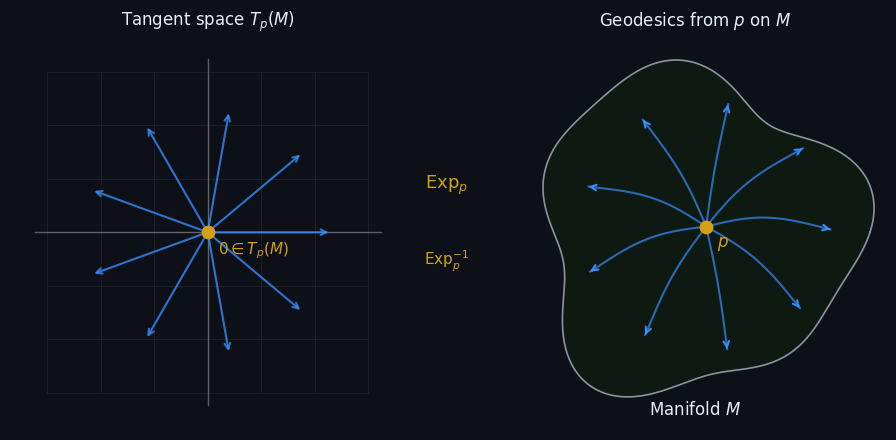

Fig 3 saved.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), facecolor=BG)

# ---- LEFT: Tangent space T_p(M) with geodesic directions ----
ax1 = axes[0]
ax1.set_facecolor(BG)
ax1.set_aspect('equal')
ax1.axis('off')

# Tangent plane grid
for xi in np.linspace(-1.3, 1.3, 7):
    ax1.plot([xi, xi], [-1.3, 1.3], color='#1c2128', lw=0.7)
    ax1.plot([-1.3, 1.3], [xi, xi], color='#1c2128', lw=0.7)

ax1.plot([-1.4, 1.4], [0, 0], color=MUTED, lw=1.0, alpha=0.6)
ax1.plot([0, 0], [-1.4, 1.4], color=MUTED, lw=1.0, alpha=0.6)

# Several tangent vectors (geodesic directions)
angles = np.linspace(0, 2*np.pi, 9, endpoint=False)
for ang in angles:
    dx, dy = 1.0*np.cos(ang), 1.0*np.sin(ang)
    ax1.annotate('', xy=(dx, dy), xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=BLUE,
                                 lw=1.5, alpha=0.8))

# Point p at origin
ax1.scatter([0], [0], color=GOLD, s=80, zorder=10)
ax1.text(0.08, -0.18, r'$0\in T_p(M)$', color=GOLD, fontsize=11)
ax1.set_title(r'Tangent space $T_p(M)$', color=TEXT, fontsize=12, pad=6)
ax1.set_xlim(-1.6, 1.6)
ax1.set_ylim(-1.6, 1.6)

# ---- RIGHT: Manifold M with geodesics ----
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_aspect('equal')
ax2.axis('off')

# Draw a blob manifold
theta_b = np.linspace(0, 2*np.pi, 300)
r_b = 1.4 + 0.15*np.cos(3*theta_b) + 0.1*np.sin(5*theta_b)
xb = r_b * np.cos(theta_b)
yb = r_b * np.sin(theta_b)
ax2.fill(xb, yb, color='#0d1f0d', alpha=0.6)
ax2.plot(xb, yb, color=MUTED, lw=1.2)

# Geodesics radiating from p (curved, simulated with slight curvature)
p_pos = np.array([0.1, 0.05])  # point p on manifold
for ang in np.linspace(0, 2*np.pi, 9, endpoint=False):
    # Curved geodesic: slight sinusoidal deviation
    s = np.linspace(0, 1.1, 50)
    curve = 0.08 * np.sin(np.pi * s) * np.sin(ang + np.pi/2)
    gx = p_pos[0] + s * np.cos(ang) + curve * (-np.sin(ang))
    gy = p_pos[1] + s * np.sin(ang) + curve * np.cos(ang)
    # Clip to manifold boundary (approximate)
    mask = np.sqrt(gx**2 + gy**2) < 1.38
    if mask.sum() > 1:
        ax2.plot(gx[mask], gy[mask], color=BLUE, lw=1.5, alpha=0.7)
        # Arrow at end
        idx = mask.sum() - 1
        if idx > 0:
            ax2.annotate('', xy=(gx[mask][idx], gy[mask][idx]),
                         xytext=(gx[mask][idx-2], gy[mask][idx-2]),
                         arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5))

# Point p
ax2.scatter(*p_pos, color=GOLD, s=80, zorder=10)
ax2.text(p_pos[0]+0.1, p_pos[1]-0.18, r'$p$', color=GOLD,
         fontsize=12, fontweight='bold')
ax2.text(0, -1.62, r'Manifold $M$', color=TEXT, fontsize=12, ha='center')
ax2.set_title(r'Geodesics from $p$ on $M$', color=TEXT, fontsize=12, pad=6)
ax2.set_xlim(-1.7, 1.7)
ax2.set_ylim(-1.75, 1.75)

# Arrow between panels
fig.text(0.495, 0.57, r'$\mathrm{Exp}_p$', color=GOLD,
         fontsize=13, ha='center')
fig.text(0.495, 0.40, r'$\mathrm{Exp}_p^{-1}$', color=GOLD,
         fontsize=11, ha='center')

plt.tight_layout()
plt.savefig('figures/gr_ch3_fig03_normal_coords.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 3 saved.')

## Fig 4: Holonomy — Parallel Transport Around a Loop (2D Schematic)

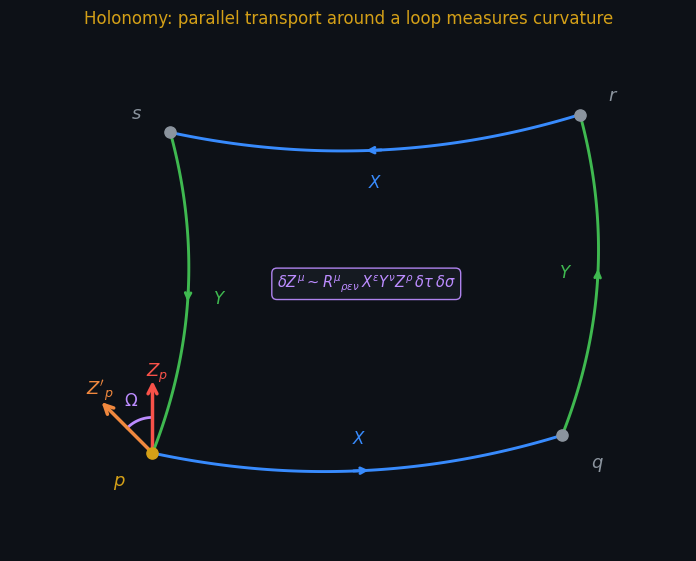

Fig 4 saved.


In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5), facecolor=BG)
ax.set_facecolor(BG); ax.set_aspect('equal'); ax.axis('off')

p = np.array([0.5,  0.4])
q = np.array([2.8,  0.5])
r = np.array([2.9,  2.3])
s = np.array([0.6,  2.2])

def draw_arc(ax, A, B, color, lpos=0.5, label=None, bow=0.18, lw=2.1):
    t = np.linspace(0, 1, 80)
    pts = np.outer(1-t, A) + np.outer(t, B)
    perp = np.array([-(B-A)[1], (B-A)[0]])
    perp = perp/(np.linalg.norm(perp)+1e-8)*bow
    pts += np.outer(4*t*(1-t), perp)
    ax.plot(pts[:,0], pts[:,1], color=color, lw=lw, zorder=4)
    idx = int(len(t)*lpos)
    ax.annotate('', xy=pts[min(idx+2,len(pts)-1)], xytext=pts[max(idx-2,0)],
                arrowprops=dict(arrowstyle='->', color=color, lw=lw))
    if label:
        dp = pts[idx+2]-pts[idx-2]
        perp2 = np.array([-dp[1],dp[0]])
        perp2 = perp2/(np.linalg.norm(perp2)+1e-8)*0.18
        ax.text(*(pts[idx]+perp2), label, color=color, fontsize=12,
                ha='center', va='center', fontweight='bold')

draw_arc(ax, p, q, BLUE,  lpos=0.50, label=r'$X$', bow=-0.15)
draw_arc(ax, q, r, GREEN, lpos=0.50, label=r'$Y$', bow=-0.15)
draw_arc(ax, r, s, BLUE,  lpos=0.50, label=r'$X$', bow= 0.15)
draw_arc(ax, s, p, GREEN, lpos=0.50, label=r'$Y$', bow= 0.15)

for pt, lbl, off, col in [
    (p, r'$p$', np.array([-0.22, -0.18]), GOLD),
    (q, r'$q$', np.array([ 0.16, -0.18]), MUTED),
    (r, r'$r$', np.array([ 0.16,  0.08]), MUTED),
    (s, r'$s$', np.array([-0.22,  0.08]), MUTED),
]:
    ax.scatter(*pt, color=col, s=65, zorder=8)
    ax.text(*(pt+off), lbl, color=col, fontsize=13, fontweight='bold')

scale = 0.42

v0 = np.array([0.0, scale])
ax.annotate('', xy=p+v0, xytext=p,
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=16))
ax.text(p[0]+0.09, p[1]+scale*1.02, r'$Z_p$',
        color=RED, fontsize=13, fontweight='bold', ha='right')

angle = np.radians(45)
v1 = np.array([np.cos(np.pi/2+angle), np.sin(np.pi/2+angle)])*scale
ax.annotate('', xy=p+v1, xytext=p,
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.5, mutation_scale=16))
ax.text(p[0]+v1[0]*1.0, p[1]+v1[1]*1.1, r"$Z'_p$",
        color=ORANGE, fontsize=13, fontweight='bold', ha='center')

arc_start = np.radians(90)
arc_end   = np.radians(90)+angle
theta_arc = np.linspace(arc_start, arc_end, 30)
r_arc = 0.20
ax.plot(p[0]+r_arc*np.cos(theta_arc), p[1]+r_arc*np.sin(theta_arc),
        color=PURPLE, lw=2.0)
mid_angle = (arc_start+arc_end)/2
ax.text(p[0]+0.32*np.cos(mid_angle), p[1]+0.32*np.sin(mid_angle),
        r'$\Omega$', color=PURPLE, fontsize=12, ha='center', va='center')

cx, cy = (p+q+r+s)/4
ax.text(cx, cy,
        r'$\delta Z^\mu \sim R^\mu{}_{\rho\epsilon\nu}\,X^\epsilon Y^\nu Z^\rho\,\delta\tau\,\delta\sigma$',
        color=PURPLE, fontsize=10.5, ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#161b22',
                  edgecolor=PURPLE, alpha=0.92))

ax.set_xlim(-0.3, 3.5); ax.set_ylim(-0.15, 2.75)
ax.set_title(r'Holonomy: parallel transport around a loop measures curvature',
             color=GOLD, fontsize=12, pad=8)
plt.tight_layout(pad=0.3)
plt.savefig('figures/gr_ch3_fig04_holonomy.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 4 saved.')


In [6]:
import shutil
shutil.make_archive('gr_ch03_figures', 'zip', '.', 'figures')
print('ZIP created: gr_ch03_figures.zip')
try:
    from google.colab import files
    files.download('gr_ch03_figures.zip')
except ImportError:
    print('Not in Colab — find gr_ch03_figures.zip in current directory.')

ZIP created: gr_ch03_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>